# 02 — Model development, controlled training and every epoch

Prerequisite: notebook 01 completed its data audit. **No old checkpoint, prediction or model result is available to this run.** All independent arms start from scratch; only optional fine-tuning loads the league checkpoint created here.

## Control, treatment and fixed settings
Control: Arsenal-only MLP on 815 training fixtures. Treatment: independent league-wide MLP on 7,977 training fixtures (including Arsenal). Optional extension: specialize the best league model on those same Arsenal training fixtures. Logistic models and a league class prior are reference controls.

39→32→16→3, ReLU, dropout 0.1, unweighted cross-entropy, AdamW learning rate 1e-4, weight decay 0.01, batch 256, seed 42, maximum 100 epochs, patience 20 and min_delta 1e-4. All checkpoints use the same 74 Arsenal validation fixtures. This compares practical pipelines under an epoch cap; the league gets more updates per epoch.

**Reproducibility rerun after test inspection.** No seed or setting is changed to manufacture different results. Seed resets make corresponding reruns deterministic; independent training arms need not have identical learned weights or predictions.

In [1]:
from pathlib import Path
import sys, json
PROJECT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'experiments/study.py').exists())
sys.path.insert(0,str(PROJECT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from experiments import study, train
DATA=study.DATA; RUN=study.RUN
plt.rcParams.update({'font.size':11,'figure.figsize':(11,5),'axes.spines.top':False,'axes.spines.right':False})
BLUE='#236B8E'; GOLD='#B78126'; GREY='#737373'
def finish(name):
    plt.tight_layout()
    plt.savefig(RUN/'figures'/f'{name}.png',dpi=150,bbox_inches='tight')
    plt.show()

display(study.initialize_training())
display(pd.Series(train.CONFIG))
model=train.network(39)
print(model)
print('Trainable parameters:',sum(p.numel() for p in model.parameters()))
print('Objective: torch.nn.CrossEntropyLoss, raw logits, class order',train.CLASSES)

,split,EPL_rows,Arsenal_rows
0,train,7977,815
1,validation,730,74
2,test,732,75


seed                                     42
max_epochs                              100
patience                                 20
min_delta                            0.0001
lr                                   0.0001
weight_decay                           0.01
batch_size                              256
hidden                             [32, 16]
dropout                                 0.1
selection       Arsenal validation log loss
threads                                   2
dtype: object

Sequential(
  (0): Linear(in_features=39, out_features=32, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.1, inplace=False)
  (3): Linear(in_features=32, out_features=16, bias=True)
  (4): ReLU()
  (5): Linear(in_features=16, out_features=3, bias=True)
)
Trainable parameters: 1859
Objective: torch.nn.CrossEntropyLoss, raw logits, class order ['A', 'D', 'H']


## 1. Train the Arsenal-only control
The following output is generated live by the training loop: online training loss, end-of-epoch Arsenal validation loss/accuracy, selected checkpoint, patience and cumulative optimizer steps. Test scores are not computed per epoch.

In [2]:
display(pd.Series(study.fit_stage('arsenal_mlp')))


START arsenal_mlp: seed=42, initial=None, rows=815


arsenal_mlp epoch=001 train_loss=1.089137971 val_loss=1.081805110 val_acc=0.486486 best_epoch=001 saved=True patience=0/20 steps=4


arsenal_mlp epoch=002 train_loss=1.086166256 val_loss=1.079540133 val_acc=0.513514 best_epoch=002 saved=True patience=0/20 steps=8


arsenal_mlp epoch=003 train_loss=1.084127313 val_loss=1.077311635 val_acc=0.527027 best_epoch=003 saved=True patience=0/20 steps=12


arsenal_mlp epoch=004 train_loss=1.082825731 val_loss=1.075055599 val_acc=0.527027 best_epoch=004 saved=True patience=0/20 steps=16


arsenal_mlp epoch=005 train_loss=1.080569366 val_loss=1.072783828 val_acc=0.540541 best_epoch=005 saved=True patience=0/20 steps=20


... (93 outputs left out)

arsenal_mlp epoch=099 train_loss=0.927735759 val_loss=0.865270376 val_acc=0.702703 best_epoch=099 saved=True patience=0/20 steps=396


arsenal_mlp epoch=100 train_loss=0.929188437 val_loss=0.864434838 val_acc=0.702703 best_epoch=100 saved=True patience=0/20 steps=400


END arsenal_mlp: best_epoch=100, epochs=100, stop=maximum epochs


model                                                                arsenal_mlp
best_epoch                                                                   100
epochs_run                                                                   100
validation_arsenal_log_loss                                             0.864435
training_rows                                                                815
checkpoint_sha256              66a872e6c2b7e900069cf1e1c178b02f47494040c1f9a1...
dtype: object

## 2. Train the independent league challenger
This constructs a fresh model and a new scaler fitted only on league training rows. Resetting seed 42 gives the same initial tensors as the Arsenal model, but it does not copy its learned weights. Data, gradient updates and the resulting fitted model differ.

In [3]:
display(pd.Series(study.fit_stage('league_mlp')))
display(pd.DataFrame(json.loads((study.MODELS/'frozen_validation_comparison.json').read_text())).T)


START league_mlp: seed=42, initial=None, rows=7977


league_mlp epoch=001 train_loss=1.087098465 val_loss=1.068020344 val_acc=0.540541 best_epoch=001 saved=True patience=0/20 steps=32


league_mlp epoch=002 train_loss=1.076027052 val_loss=1.047609329 val_acc=0.594595 best_epoch=002 saved=True patience=0/20 steps=64


league_mlp epoch=003 train_loss=1.064099416 val_loss=1.023564696 val_acc=0.608108 best_epoch=003 saved=True patience=0/20 steps=96


league_mlp epoch=004 train_loss=1.051737241 val_loss=0.998163402 val_acc=0.648649 best_epoch=004 saved=True patience=0/20 steps=128


league_mlp epoch=005 train_loss=1.040044806 val_loss=0.972663283 val_acc=0.662162 best_epoch=005 saved=True patience=0/20 steps=160

... (94 outputs left out)

league_mlp epoch=100 train_loss=0.969895185 val_loss=0.796874046 val_acc=0.675676 best_epoch=098 saved=False patience=2/20 steps=3200

END league_mlp: best_epoch=98, epochs=100, stop=maximum epochs


model                                                                 league_mlp
best_epoch                                                                    98
epochs_run                                                                   100
validation_arsenal_log_loss                                             0.796609
training_rows                                                               7977
checkpoint_sha256              0416130b3fd2eab7db5f86512162569e862c82f5014f61...
dtype: object

,log_loss,brier_multiclass,accuracy,n
arsenal_mlp,0.864435,0.503668,0.702703,74.0
league_mlp,0.796609,0.453318,0.689189,74.0


## 3. Optional Arsenal specialization — enabled before evaluation
The independent comparison is frozen above. Fine-tuning starts from this run's best league checkpoint and retains its scaler, with a fresh AdamW optimizer. Its inherited validation loss is eligible as epoch zero. The training budget and stopping rules remain unchanged.

In [4]:
display(pd.Series(study.fit_stage('league_to_arsenal_mlp')))


START league_to_arsenal_mlp: seed=42, initial=/workspace/Premier-League-Research/results/current/models/league_mlp_best.pt, rows=815


league_to_arsenal_mlp epoch=000 initial_validation_loss=0.796609044


league_to_arsenal_mlp epoch=001 train_loss=0.906065536 val_loss=0.796372890 val_acc=0.689189 best_epoch=001 saved=True patience=0/20 steps=4


league_to_arsenal_mlp epoch=002 train_loss=0.901878462 val_loss=0.796406686 val_acc=0.689189 best_epoch=001 saved=False patience=1/20 steps=8


league_to_arsenal_mlp epoch=003 train_loss=0.909410107 val_loss=0.796657383 val_acc=0.689189 best_epoch=001 saved=False patience=2/20 steps=12


league_to_arsenal_mlp epoch=004 train_loss=0.904080152 val_loss=0.796974659 val_acc=0.689189 best_epoch=001 saved=False patience=3/20 steps=16


... (15 outputs left out)

league_to_arsenal_mlp epoch=020 train_loss=0.901485599 val_loss=0.799062073 val_acc=0.702703 best_epoch=001 saved=False patience=19/20 steps=80


league_to_arsenal_mlp epoch=021 train_loss=0.903576806 val_loss=0.799120426 val_acc=0.702703 best_epoch=001 saved=False patience=20/20 steps=84


END league_to_arsenal_mlp: best_epoch=1, epochs=21, stop=patience


model                                                      league_to_arsenal_mlp
best_epoch                                                                     1
epochs_run                                                                    21
validation_arsenal_log_loss                                             0.796373
training_rows                                                                815
checkpoint_sha256              196f1914616dcd22d3ec8d6ddc37560140bdc9eb10cf94...
dtype: object

## 4. Fit fixed reference controls and freeze selection
Logistic regression uses C=1, max_iter=2000, training-only standardization and seed 42; the prior uses league training class frequencies. Selection includes all arms and uses Arsenal validation loss only.

In [5]:
training,selection,checks=study.controls_and_freeze()
display(training.drop(columns='checkpoint_sha256'))
display(pd.Series(selection['validation_scores'],name='Arsenal validation log loss'))
print('Selected candidate:',selection['selected_model'])
display(pd.Series(checks))

,model,best_epoch,epochs_run,validation_arsenal_log_loss,training_rows
0,arsenal_mlp,100,100,0.864435,815
1,league_mlp,98,100,0.796609,7977
2,league_to_arsenal_mlp,1,21,0.796373,815


arsenal_mlp              0.864435
league_mlp               0.796609
league_to_arsenal_mlp    0.796373
league_logistic          0.796205
arsenal_logistic         0.851985
league_prior             1.040187
Name: Arsenal validation log loss, dtype: float64

Selected candidate: league_logistic


independent_models_start_fresh              True
same_seed_same_initial_weights              True
trained_models_have_different_weights       True
fine_tuning_loads_current_league_weights    True
all_fits_changed_weights                    True
dtype: bool

## 5. Learning curves and full epoch tables
Common loss scales make magnitudes comparable, but training populations differ and dropout is active only during training. The validation curves use identical fixtures. Best epochs are marked; reaching epoch 100 does not establish convergence.

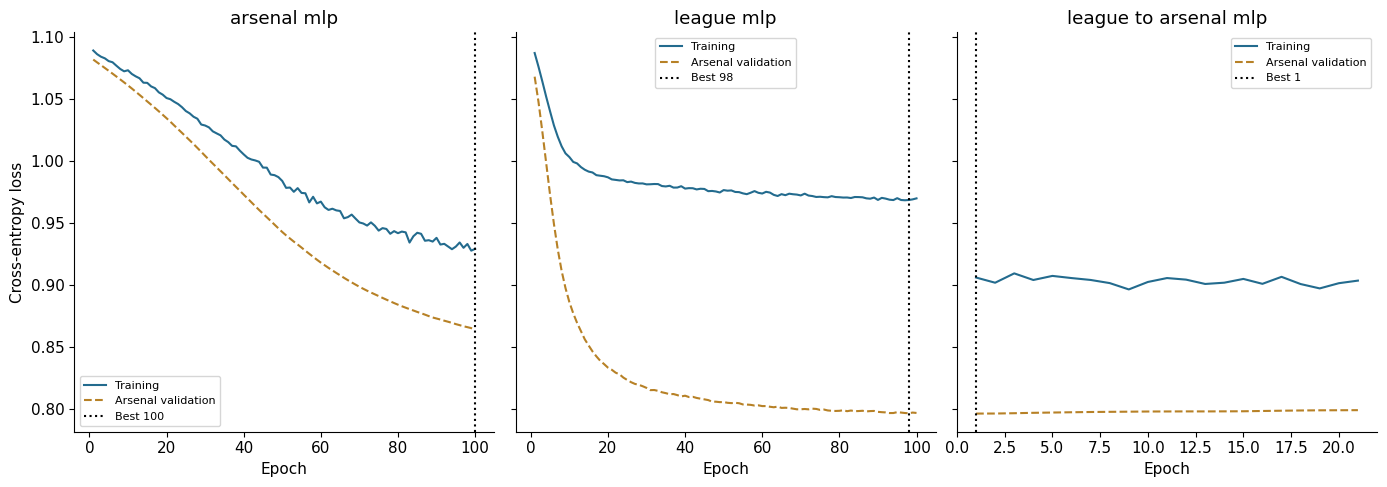

### arsenal_mlp

,epoch,training_log_loss,validation_arsenal_log_loss,validation_arsenal_accuracy,best_validation_loss,best_epoch_so_far,checkpoint_saved,patience_used,optimizer_steps,epoch_seconds
0,1,1.089138,1.081805,0.486486,1.081805,1,True,0,4,0.007023
1,2,1.086166,1.079540,0.513514,1.079540,2,True,0,8,0.005859
2,3,1.084127,1.077312,0.527027,1.077312,3,True,0,12,0.004859
3,4,1.082826,1.075056,0.527027,1.075056,4,True,0,16,0.004444
4,5,1.080569,1.072784,0.540541,1.072784,5,True,0,20,0.004479
5,6,1.079655,1.070475,0.540541,1.070475,6,True,0,24,0.004505
6,7,1.076868,1.068149,0.540541,1.068149,7,True,0,28,0.004232
7,8,1.074225,1.065802,0.540541,1.065802,8,True,0,32,0.004421
8,9,1.072349,1.063411,0.540541,1.063411,9,True,0,36,0.004192
9,10,1.073181,1.060987,0.554054,1.060987,10,True,0,40,0.004282


### league_mlp

,epoch,training_log_loss,validation_arsenal_log_loss,validation_arsenal_accuracy,best_validation_loss,best_epoch_so_far,checkpoint_saved,patience_used,optimizer_steps,epoch_seconds
100,1,1.087098,1.068020,0.540541,1.068020,1,True,0,32,0.020346
101,2,1.076027,1.047609,0.594595,1.047609,2,True,0,64,0.019722
102,3,1.064099,1.023565,0.608108,1.023565,3,True,0,96,0.019609
103,4,1.051737,0.998163,0.648649,0.998163,4,True,0,128,0.019748
104,5,1.040045,0.972663,0.662162,0.972663,5,True,0,160,0.019577
105,6,1.028717,0.949228,0.675676,0.949228,6,True,0,192,0.020750
106,7,1.019569,0.928597,0.675676,0.928597,7,True,0,224,0.019938
107,8,1.011865,0.911380,0.675676,0.911380,8,True,0,256,0.019914
108,9,1.006175,0.897544,0.675676,0.897544,9,True,0,288,0.019954
109,10,1.003229,0.886274,0.675676,0.886274,10,True,0,320,0.019655


### league_to_arsenal_mlp

,epoch,training_log_loss,validation_arsenal_log_loss,validation_arsenal_accuracy,best_validation_loss,best_epoch_so_far,checkpoint_saved,patience_used,optimizer_steps,epoch_seconds
200,1,0.906066,0.796373,0.689189,0.796373,1,True,0,4,0.003945
201,2,0.901878,0.796407,0.689189,0.796373,1,False,1,8,0.003454
202,3,0.909410,0.796657,0.689189,0.796373,1,False,2,12,0.004656
203,4,0.904080,0.796975,0.689189,0.796373,1,False,3,16,0.002756
204,5,0.907378,0.797208,0.689189,0.796373,1,False,4,20,0.003193
205,6,0.905636,0.797432,0.689189,0.796373,1,False,5,24,0.003034
206,7,0.904114,0.797634,0.689189,0.796373,1,False,6,28,0.003487
207,8,0.901585,0.797771,0.689189,0.796373,1,False,7,32,0.003084
208,9,0.896478,0.797894,0.689189,0.796373,1,False,8,36,0.003291
209,10,0.902493,0.798029,0.689189,0.796373,1,False,9,40,0.003382


In [6]:
fig,axes=plt.subplots(1,3,figsize=(14,5),sharey=True)
all_history=[]
for ax,row in zip(axes,training.itertuples()):
    h=pd.read_csv(study.MODELS/f'{row.model}_history.csv');all_history.append(h.assign(model=row.model))
    ax.plot(h.epoch,h.training_log_loss,color=BLUE,label='Training')
    ax.plot(h.epoch,h.validation_arsenal_log_loss,color=GOLD,linestyle='--',label='Arsenal validation')
    ax.axvline(row.best_epoch,color='black',linestyle=':',label=f'Best {row.best_epoch}')
    ax.set(title=row.model.replace('_',' '),xlabel='Epoch');ax.legend(fontsize=8)
axes[0].set_ylabel('Cross-entropy loss');finish('11_learning_curves')
history=pd.concat(all_history,ignore_index=True);history.to_csv(study.MODELS/'all_epochs.csv',index=False)
lines=['# Every epoch from the fresh controlled execution','',f"Run ID: `{study.manifest()['run_id']}`. Test not scored per epoch. Training loss includes dropout; validation loss uses evaluation mode.",'','| Model | Epoch | Train loss | Arsenal validation loss | Validation accuracy | Best epoch | Patience | Updates |','|---|---:|---:|---:|---:|---:|---:|---:|']
for row in history.itertuples():
    lines.append(f'| {row.model} | {row.epoch} | {row.training_log_loss:.9f} | {row.validation_arsenal_log_loss:.9f} | {row.validation_arsenal_accuracy:.6f} | {row.best_epoch_so_far} | {row.patience_used} | {row.optimizer_steps} |')
(study.MODELS/'EVERY_EPOCH.md').write_text(chr(10).join(lines)+chr(10))
for name,group in history.groupby('model',sort=False):
    display(Markdown('### '+name))
    with pd.option_context('display.max_rows',None,'display.max_columns',None):display(group.drop(columns='model').round(9))

## 6. Execution evidence
The run records timestamps, initial and selected-weight hashes, source/configuration hashes, transfer ancestry and optimizer updates. Equal initial hashes under seed 42 are expected. Different learned weights between the independent arms demonstrate that the two trained models have not been conflated. These checks verify implementation behavior; they do not establish statistical superiority.

In [7]:
audits=pd.DataFrame({name:json.loads((study.MODELS/f'{name}_execution.json').read_text()) for name in study.NEURAL}).T
display(audits)
print('Total optimizer updates:',audits.optimizer_steps.sum())
print('No test metric file yet:',not (RUN/'evaluation/metrics.csv').exists())
assert not (RUN/'evaluation/metrics.csv').exists()
print('Stage:',study.manifest()['stage'])

,model,started_utc,initial_checkpoint,initial_weights_sha256,initial_checkpoint_sha256,training_rows,validation_rows,optimizer_steps,finished_utc,elapsed_seconds,best_weights_sha256,best_epoch,epochs_run,stop_reason
arsenal_mlp,arsenal_mlp,2026-10-26T05:55:32.977297+00:00,None,a82b44ca3abc7438de0fbd0854c518ff90448624564e79...,None,815,74,400,2026-10-26T05:55:34.010744+00:00,1.04544,09e8eea1851b750f2da9bb1b27f73c1100002ebc1f3ab8...,100,100,maximum epochs
league_mlp,league_mlp,2026-10-26T05:55:34.057103+00:00,None,a82b44ca3abc7438de0fbd0854c518ff90448624564e79...,None,7977,74,3200,2026-10-26T05:55:36.282288+00:00,2.229615,6491ec3acec3c202f9476ed554dad683191400613eb8a9...,98,100,maximum epochs
league_to_arsenal_mlp,league_to_arsenal_mlp,2026-10-26T05:55:36.340586+00:00,/workspace/Premier-League-Research/results/cur...,6491ec3acec3c202f9476ed554dad683191400613eb8a9...,0416130b3fd2eab7db5f86512162569e862c82f5014f61...,815,74,84,2026-10-26T05:55:36.627510+00:00,0.289673,1ef8bbf329a100e20134b3d4f3bc6d3148faab625b3bdc...,1,21,patience


Total optimizer updates: 3684
No test metric file yet: True
Stage: models_frozen
